<a href="https://colab.research.google.com/github/enyachang1119-debug/DS2002/blob/main/Copy_of_2026_11_13_%E2%80%94_Visualization_Challenge_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

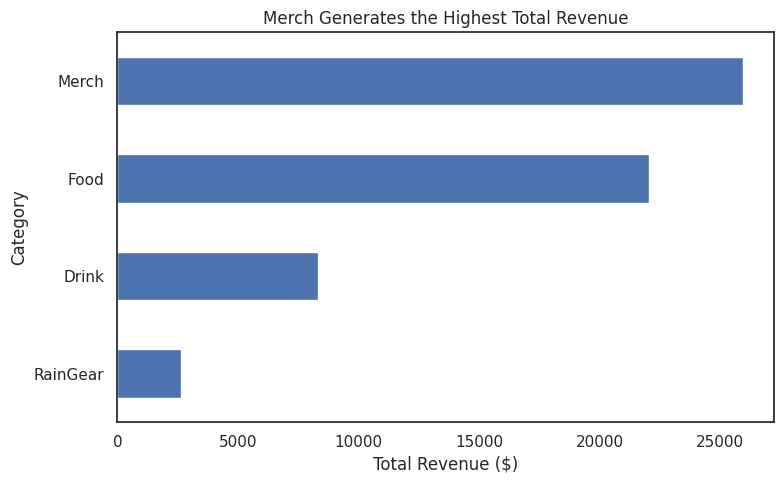

In [2]:
# TODO
revenue_by_category = df.groupby("category")["revenue"].sum().sort_values() # Calculate total revenue for each category and sort in ascending order
ax = revenue_by_category.plot(kind="barh", figsize=(8, 5)) # Create a horizontal bar chart

# Add chart title and axis labels
ax.set_title("Merch Generates the Highest Total Revenue")
ax.set_xlabel("Total Revenue ($)")
ax.set_ylabel("Category")

# Start the x-axis at zero
ax.set_xlim(left=0)

plt.tight_layout()
plt.show()


**Caption:** _The horizontal bar chart compares total revenue across product categories, sorted from lowest to highest. Merch generates the highest revenue with approximately $26,000, followed by Food for $22,000, and RainGear contributes the least revenue._

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

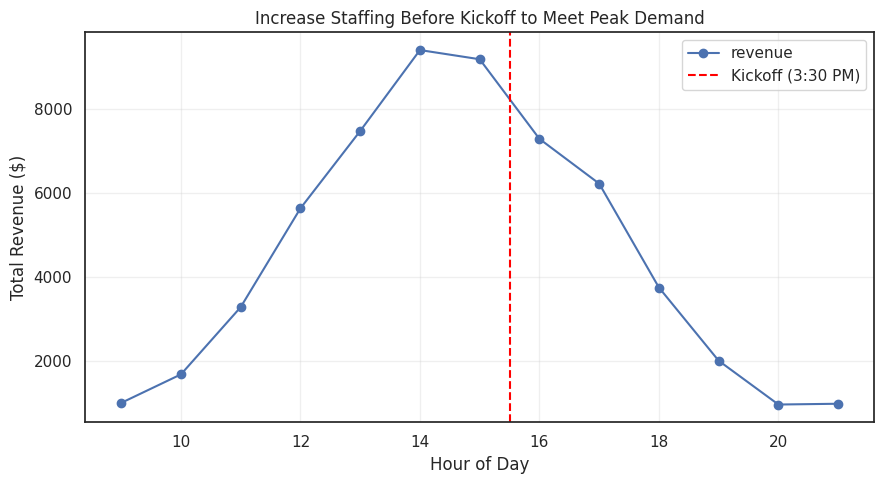

In [3]:
# TODO
revenue_by_hour = df.groupby("hour")["revenue"].sum().sort_index() # Calculate total revenue for each hour
ax = revenue_by_hour.plot(kind="line", marker="o", figsize=(9, 5)) # Create a line chart
ax.axvline(x=15.5, color="red", linestyle="--", label="Kickoff (3:30 PM)") # Mark kickoff time at 15.5 (3:30 PM)

# Add title and axis labels
ax.set_title("Increase Staffing Before Kickoff to Meet Peak Demand")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Total Revenue ($)")

# Add legend and grid
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Caption:** _Revenue peaks around 2–3 PM, before the 3:30 PM kickoff, and gradually declines afterward. This suggests that additional staff should be scheduled before kickoff to handle the higher customer demand._

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

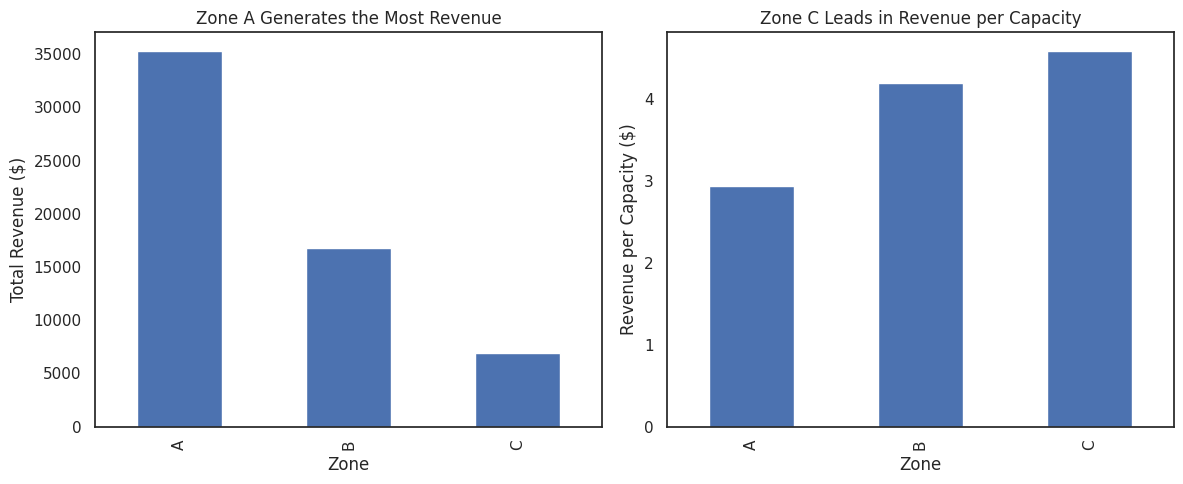

In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacit
revenue_by_zone = df.groupby("zone")["revenue"].sum() # Calculate total revenue for each zone
revenue_per_capacity = revenue_by_zone / pd.Series(zone_capacity) # Calculate revenue per unit of capacity
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) # Create two side-by-side charts

# Left chart: Raw revenue by zone
revenue_by_zone.plot(kind="bar", ax=axes[0])
axes[0].set_title("Zone A Generates the Most Revenue")
axes[0].set_xlabel("Zone")
axes[0].set_ylabel("Total Revenue ($)")
axes[0].set_ylim(bottom=0)

# Right chart: Revenue normalized by capacity
revenue_per_capacity.plot(kind="bar", ax=axes[1])
axes[1].set_title("Zone C Leads in Revenue per Capacity")
axes[1].set_xlabel("Zone")
axes[1].set_ylabel("Revenue per Capacity ($)")
axes[1].set_ylim(bottom=0)

plt.tight_layout()
plt.show()


**Caption, and which panel I would present:** _Zone A generates the highest total revenue and Zone C has the highest revenue per unit of capacity. I would show managers the raw revenue chart to understand each zone's overall sales contribution, and the normalized chart to compare revenue performance fairly across zones of different sizes._

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

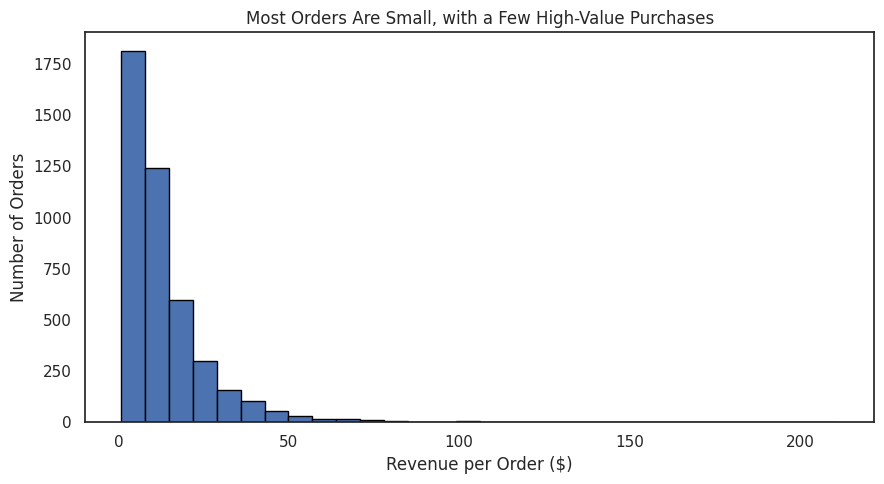

In [5]:
# TODO
# Create a histogram of individual order revenue
plt.figure(figsize=(9, 5))
plt.hist(df["revenue"], bins=30, edgecolor="black")

# Add chart title and axis labels
plt.title("Most Orders Are Small, with a Few High-Value Purchases")
plt.xlabel("Revenue per Order ($)")
plt.ylabel("Number of Orders")

# Start the y-axis at zero
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()


**Caption:** _The histogram shows a right-skewed distribution, with most orders concentrated below $20 and a few much larger orders. Unlike total revenue, this chart reveals that overall sales come from many small purchases and a relatively small number of high-value orders._

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

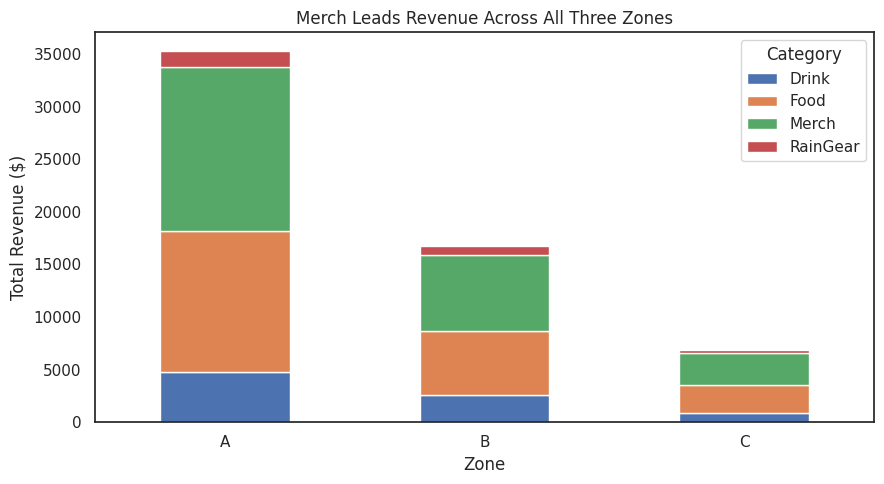

In [6]:
# TODO
revenue_zone_category = df.groupby(["zone", "category"])["revenue"].sum().unstack(fill_value=0) # Calculate revenue by zone and product category
ax = revenue_zone_category.plot(kind="bar", stacked=True, figsize=(9, 5)) # Create a stacked bar chart

# Add chart title and axis labels
ax.set_title("Merch Leads Revenue Across All Three Zones")
ax.set_xlabel("Zone")
ax.set_ylabel("Total Revenue ($)")

# Start the y-axis at zero
ax.set_ylim(bottom=0)

# Add legend
ax.legend(title="Category")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Caption:** _The stacked bar chart shows the revenue composition across zones. Although Zone A generates the highest total revenue, Merch is the leading category in all three zones, accounting for approximately 44% of revenue in each. This suggests that product purchasing patterns are relatively consistent across zones, which can help guide inventory allocation._

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

_a) Chart 3 changed my perspective because Zone A generated the highest total revenue, but Zone C performed the best after adjusting for capacity. This showed me that higher total revenue does not necessarily mean better performance when zones have different sizes._

_b) Raw revenue is more useful when managers want to understand each zone's overall contribution to sales or allocate resources based on total demand. Revenue per unit of capacity is more useful when comparing performance across zones of different sizes because it accounts for differences in capacity and provides a fairer comparison._